# IPSD — Minggu 7: Klasifikasi: Naïve Bayes & KNN

**Mata Kuliah:** Infrastruktur dan Platform untuk Sains Data  
**Sub-CLO:** Sub-CLO-09-4-1  
**AI Level:** L2  

**AI Level 2 — AI-Assisted Idea Generation and Structuring.** AI boleh digunakan untuk brainstorming, decomposition, alternatif struktur/pipeline, dan pertanyaan klarifikasi. Jawaban akhir, kode akhir, keputusan, dan interpretasi harus dibuat mahasiswa. Simpan prompt log.

## Capaian Praktikum
- Mengimplementasikan Gaussian Naïve Bayes dan KNN.
- Menganalisis pengaruh skala data pada KNN.
- Membandingkan model dengan metrik klasifikasi.

**Dataset:** Wine dataset dari scikit-learn.

## Alur Praktikum
- 1. Train GaussianNB.
- 2. Train KNN sebelum dan sesudah StandardScaler.
- 3. Buat confusion matrix dan classification report.
- 4. Uji beberapa nilai k dan pilih berdasarkan validation sederhana.

In [1]:
from sklearn.datasets import load_wine
from sklearn.model_selection import train_test_split
from sklearn.naive_bayes import GaussianNB
from sklearn.neighbors import KNeighborsClassifier
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report

data = load_wine(as_frame=True)
X_train, X_test, y_train, y_test = train_test_split(data.data, data.target, test_size=0.25, stratify=data.target, random_state=42)

nb = GaussianNB().fit(X_train, y_train)
knn_raw = KNeighborsClassifier(n_neighbors=5).fit(X_train, y_train)
knn_scaled = make_pipeline(StandardScaler(), KNeighborsClassifier(n_neighbors=5)).fit(X_train, y_train)

for name, model in [('Naive Bayes', nb), ('KNN raw', knn_raw), ('KNN scaled', knn_scaled)]:
    pred = model.predict(X_test)
    print(name, accuracy_score(y_test, pred))

Naive Bayes 0.9777777777777777
KNN raw 0.7777777777777778
KNN scaled 0.9333333333333333


hasilnya lumayan jauh beda. naive beyas dpet akurasi sekitar 0.98, KKN yg datanya mentah cuma 0.778, dan KKN yg udh di scale naik jadi 0.93

## Latihan Terstruktur
- Bandingkan KNN tanpa scaling vs dengan scaling.
- Cari nilai k terbaik dari himpunan kandidat.
- Jelaskan kondisi kapan Naïve Bayes bisa lebih unggul atau lebih sederhana.

In [3]:
import pandas as pd

print("ukuran data:", data.data.shape)
print("jumlah per kelas:")
print(data.target.value_counts().sort_index().to_string())
print()

ukuran data: (178, 13)
jumlah per kelas:
target
0    59
1    71
2    48



datanya cuma 178 smpel dgn 13 fitur, dan ada 3 kelas (59, 71, 48) 

In [4]:
# rentang nilai tiap fitur, biar kelihatan skalanya
ringkas = data.data.describe().T[['min', 'max', 'std']].round(2)
print(ringkas.to_string())

                                 min      max     std
alcohol                        11.03    14.83    0.81
malic_acid                      0.74     5.80    1.12
ash                             1.36     3.23    0.27
alcalinity_of_ash              10.60    30.00    3.34
magnesium                      70.00   162.00   14.28
total_phenols                   0.98     3.88    0.63
flavanoids                      0.34     5.08    1.00
nonflavanoid_phenols            0.13     0.66    0.12
proanthocyanins                 0.41     3.58    0.57
color_intensity                 1.28    13.00    2.32
hue                             0.48     1.71    0.23
od280/od315_of_diluted_wines    1.27     4.00    0.71
proline                       278.00  1680.00  314.91


disini terlihat kalo fiturnya timpang bgt. proline nilainya dri 278 smpe 1680, sdgkan hue cuma 0.48 dampe 1.71 dan nonflavonoid_phenols malah cuma 0.13 smpe 0.66

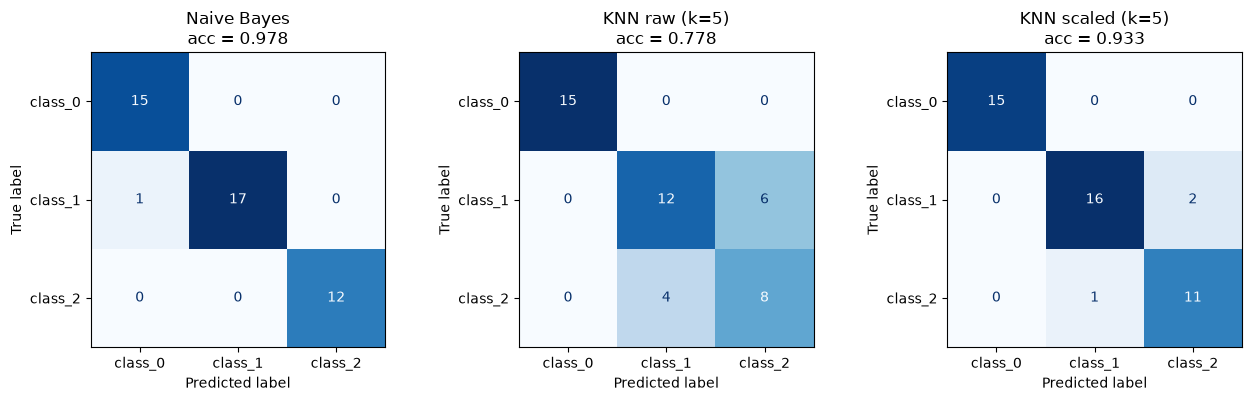

In [5]:
import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay

hasil = [('Naive Bayes', nb), ('KNN raw (k=5)', knn_raw), ('KNN scaled (k=5)', knn_scaled)]

fig, axes = plt.subplots(1, 3, figsize=(13, 4))
for ax, (name, model) in zip(axes, hasil):
    pred = model.predict(X_test)
    ConfusionMatrixDisplay(confusion_matrix(y_test, pred), display_labels=data.target_names).plot(ax=ax, colorbar=False, cmap='Blues')
    ax.set_title(f"{name}\nacc = {accuracy_score(y_test, pred):.3f}")
plt.tight_layout()
plt.show()

In [8]:
for name, model in hasil:
    print(name)
    print(classification_report(y_test, model.predict(X_test), target_names=data.target_names))

Naive Bayes
              precision    recall  f1-score   support

     class_0       0.94      1.00      0.97        15
     class_1       1.00      0.94      0.97        18
     class_2       1.00      1.00      1.00        12

    accuracy                           0.98        45
   macro avg       0.98      0.98      0.98        45
weighted avg       0.98      0.98      0.98        45

KNN raw (k=5)
              precision    recall  f1-score   support

     class_0       1.00      1.00      1.00        15
     class_1       0.75      0.67      0.71        18
     class_2       0.57      0.67      0.62        12

    accuracy                           0.78        45
   macro avg       0.77      0.78      0.77        45
weighted avg       0.79      0.78      0.78        45

KNN scaled (k=5)
              precision    recall  f1-score   support

     class_0       1.00      1.00      1.00        15
     class_1       0.94      0.89      0.91        18
     class_2       0.85      0.9

disini kelihatan kalo KKN tnpa scaling jelek di class_1 dan class_2, sdgkan class_0 aman aman aja. habis di scale, F1 class_1 jadi 0.91 dan class_2 jdi 0.88

In [10]:
# iseng cek: kalau Naive Bayes juga di-scale, hasilnya berubah nggak?
nb_scaled = make_pipeline(StandardScaler(), GaussianNB()).fit(X_train, y_train)
print("NB tanpa scaling :", accuracy_score(y_test, nb.predict(X_test)))
print("NB dengan scaling:", accuracy_score(y_test, nb_scaled.predict(X_test)))

NB tanpa scaling : 0.9777777777777777
NB dengan scaling: 0.9777777777777777


In [11]:
# validation sederhana: dari data TRAIN dipisah lagi jadi train kecil + validation
# (data test sengaja nggak disentuh dulu biar nggak "ngintip")
X_tr, X_val, y_tr, y_val = train_test_split(X_train, y_train, test_size=0.25, stratify=y_train, random_state=42)

kandidat_k = [1, 3, 5, 7, 9, 11, 13, 15, 21]

baris = []
for k in kandidat_k:
    val_raw = KNeighborsClassifier(n_neighbors=k).fit(X_tr, y_tr).score(X_val, y_val)
    val_scaled = make_pipeline(StandardScaler(), KNeighborsClassifier(n_neighbors=k)).fit(X_tr, y_tr).score(X_val, y_val)
    baris.append((k, val_raw, val_scaled))

tabel_k = pd.DataFrame(baris, columns=['k', 'val_raw', 'val_scaled']).round(3)
print(tabel_k.to_string(index=False))

 k  val_raw  val_scaled
 1    0.735       0.971
 3    0.706       0.971
 5    0.735       0.971
 7    0.676       0.971
 9    0.676       0.971
11    0.735       0.941
13    0.765       0.941
15    0.765       0.941
21    0.735       0.971


tanpa scalling, akurasi validationnya naik turun di kisaran 0.68 smpe 0.77 dan gaada pola yg jelas

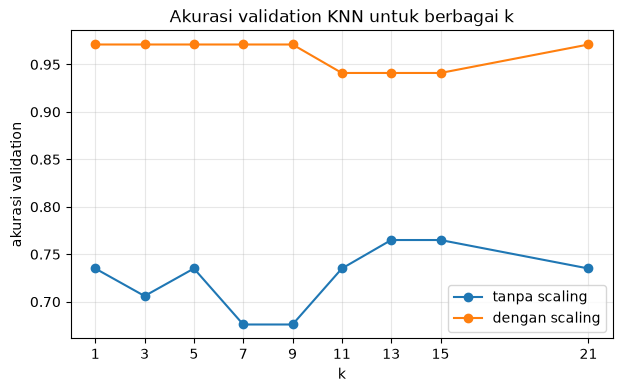

In [12]:
plt.figure(figsize=(7, 4))
plt.plot(tabel_k['k'], tabel_k['val_raw'], marker='o', label='tanpa scaling')
plt.plot(tabel_k['k'], tabel_k['val_scaled'], marker='o', label='dengan scaling')
plt.xticks(kandidat_k)
plt.xlabel('k')
plt.ylabel('akurasi validation')
plt.title('Akurasi validation KNN untuk berbagai k')
plt.legend()
plt.grid(alpha=0.3)
plt.show()

dri grafik diatas, garis tanpa scalling jelas jauh di bawah garis yg di scale. garis yg di scale hampir datar di sekitar 0.94 smpe 0.97 jadi efek scaling lebih gede dripada efek pemilihan k


aku pilih k = 3. karena bnyak k yg imbang, aku pakai pertimbangan lain.. 

k = 1, cuma ngikutin satu tetangga jdi gampang kena outlier

k = 3, sdgkan k = 3 lebih stabil dan ringan

k = 5, sbnernya juga oke.. tpi pertimbanganku tetep jatuh di k = 3

In [15]:
# eksperimen kecil: kalau data latihnya sedikit, siapa yang lebih tahan?
rng_seeds = range(30)
persen = [0.1, 0.2, 0.3, 0.5, 0.75]
hasil_ukuran = []
for p in persen:
    skor_nb, skor_knn = [], []
    for s in rng_seeds:
        Xa, Xb, ya, yb = train_test_split(data.data, data.target, train_size=p, stratify=data.target, random_state=s)
        skor_nb.append(GaussianNB().fit(Xa, ya).score(Xb, yb))
        skor_knn.append(make_pipeline(StandardScaler(), KNeighborsClassifier(n_neighbors=3)).fit(Xa, ya).score(Xb, yb))
    hasil_ukuran.append((p, len(Xa), np.mean(skor_nb), np.mean(skor_knn)))

tabel_ukuran = pd.DataFrame(hasil_ukuran, columns=['porsi_train', 'jumlah_train', 'acc_NB', 'acc_KNN_scaled']).round(3)
print(tabel_ukuran.to_string(index=False))

 porsi_train  jumlah_train  acc_NB  acc_KNN_scaled
        0.10            17   0.886           0.915
        0.20            35   0.949           0.931
        0.30            53   0.962           0.941
        0.50            89   0.971           0.951
        0.75           133   0.973           0.956


ternyata hasilnya diluar dugaan awalku, tdi sempet ngira kalo NB bakal lebih unggul di data, tpi setelah di cek disini pas di data train cuma 17 sampe, KKN scaled malah sedikit lebih tinggi. mulai dri 35 sampe ketas NB yg lebih tinggi. jadi di dataset ini perbedaan akurasinya kecil

**jadi kapan NB bisa lebih unggul atau lebih sederhana ?**

- lebih sederhana dan cepat
- ga butuh scaling
- cocok klo fiturnya kira' distribusi normal per kelas dan ga terlalu saling bergantung
- banyak fitur tapi sampel terbatas
- sebaliknya, KNN bisa lebih bagus klo batas antar kelas bentuknya rumit dan ga ngikutin distribusi normal, karena KNN ga punya asumsi bentuk distribusi bentuk sma sekali

keterbatasan = data kecil, cuma satu kali split utama pke random_state=42, sma metrik utamanya akurasi

## Luaran
Notebook + analisis perbandingan + prompt log L2.

**Bukti AI/validasi:** Prompt log; keputusan model.

## Prompt Log — wajib
Isi minimal 2 interaksi yang benar-benar Anda gunakan.

| No | Tujuan Prompt | Prompt | Ringkasan Respons AI | Keputusan Saya / Apa yang Dipakai | Verifikasi |
|---|---|---|---|---|---|
|1|Minta bantuan mencari nilai k terbaik untuk KNN|“coba revisi lagi tanpa lihat kode yg aku kasih tadi buat nyari k nya"|AI membuat pencarian k pakai validation split untuk KNN tanpa scaling dan dengan scaling. Hasilnya banyak k yang imbang di 0,971 (k = 1, 3, 5, 7, 9, 21), sedangkan k = 11, 13, 15 turun ke 0,941.|Saya pilih k = 3 karena k = 1 rawan noise. Cross-validation tidak saya pakai dan saya minta dibuang.|Notebook dijalankan ulang, dan saya cek bahwa data test tidak dipakai untuk memilih k.|
|2|cv 5 fold kyanya ga perlu deh, jadi cuma 2 aja|CV dibuang, tinggal validation untuk versi tanpa dan dengan scaling, hasil banyak k imbang di 0,971|CV ga dipake|CV ga dipake|ku hapus CV nya|

## Refleksi Singkat
1. Bagian apa yang paling terbantu oleh AI?  

paling kebantu di bagian nyusun alur latihan, pas bagian bandingin model sma nyari k

2. Bagian apa yang tetap harus Anda putuskan sendiri?  

milih nilai k [ k = 3 itu pertimbangan karena selisihnya tipis ], nentuin model mana yg dipilih buat kesimpulan, dan gecek apakah interpretasinya beneran cocok sma angka di output

3. Apa satu keterbatasan/risiko respons AI yang Anda temukan?

dugaan awal soal "NB pasti lebih unggul di data sedikit" ternyata ga muncul di eksperimen, malah KNN sedikit lebih tinggi di 17 sampel